# Rate–distortion kernels and forbidden transitions

Rate–distortion optimization has a feasible reconstruction kernel and a separately feasible dual lower bound. A plot of iterations alone would not establish optimality.

[Interactive explorer](../docs/explorer.html) · [Measurement contracts](../docs/mathematical_contracts.md) · [Course proofs](../docs/course_coverage.md)

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image

ROOT = next(
    p
    for p in [Path.cwd(), *Path.cwd().parents]
    if (p / "src/information_lab").is_dir() and (p / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))


def query(family, **wanted):
    seed = wanted.pop("seed", 41)
    records = []
    for path in sorted((ROOT / "results/reference" / family).glob("*/run.json")):
        record = json.loads(path.read_text())
        if record["seed"] == seed and all(record["config"].get(k) == v for k, v in wanted.items()):
            records.append((record, path.parent))
    if not records:
        raise ValueError("No applicable recorded evidence")
    return records


def arrays(path):
    with np.load(path / "data.npz", allow_pickle=False) as archive:
        return {key: archive[key] for key in archive.files}


def measured(record):
    display(Markdown("**Recorded configuration**"))
    print(json.dumps(record["config"], indent=2))
    print(json.dumps(record["metrics"], indent=2))


def preview(record):
    key = record["config"]["id"] + "_s" + str(record["seed"])
    display(
        Image(
            filename=str(ROOT / "assets/experiments" / record["config"]["family"] / (key + ".png"))
        )
    )

In [2]:
from information_lab.rate_distortion import solve, bernoulli_hamming, asymmetric_forbidden

source = np.array([0.5, 0.5])
cost = np.array([[0, 1], [1, 0]])
result = solve(source, cost, 2)
truth = bernoulli_hamming(0.5, result["distortion"])
print(
    "Distortion",
    result["distortion"],
    "rate interval",
    result["lower_rate_bits"],
    result["upper_rate_bits"],
    "analytic",
    truth,
)
assert result["lower_rate_bits"] - 1e-8 <= truth <= result["upper_rate_bits"] + 1e-8

Distortion 0.11920292202211753 rate interval 0.4729346589968385 0.47293465899683834 analytic 0.4729346589968384


In [3]:
forbidden = np.array([[0, np.inf], [1, 0]])
result = solve(source, forbidden, 2)
print("Kernel", result["conditional"], "analytic rate", asymmetric_forbidden(result["distortion"]))
assert result["conditional"][0, 1] == 0

Kernel [[1.         0.        ]
 [0.15651764 0.84348236]] analytic rate 0.6692991358785452


In [4]:
records = query("rate_distortion", task="asymmetric_forbidden")
records = sorted(records, key=lambda rp: rp[0]["metrics"]["distortion"])
plt.plot(
    [r["metrics"]["distortion"] for r, _ in records],
    [r["metrics"]["upper_rate_bits"] for r, _ in records],
    "o-",
    label="Feasible rate",
)
plt.plot(
    [r["metrics"]["distortion"] for r, _ in records],
    [r["metrics"]["analytic_rate_bits"] for r, _ in records],
    "--",
    label="Analytic",
)
plt.xlabel("Expected distortion")
plt.ylabel("bits/source symbol")
plt.legend()
plt.show()

**Recorded configuration**

{
  "family": "rate_distortion",
  "id": "discretized_gaussian_06",
  "task": "discretized_gaussian",
  "beta": 0.7,
  "tolerance": 1e-06,
  "accelerate": true,
  "stochastic": false
}
{
  "distortion": 0.7137569931749417,
  "upper_rate_bits": 0.24810940622867098,
  "lower_rate_bits": 0.24810937317346274,
  "gap_bits": 3.305520823726482e-08,
  "beta_nats": 0.7,
  "iterations": 2001,
  "converged": true,
  "acceleration_used": true,
  "algorithm": "BA with optional convex marginal warm start",
  "analytic_rate_bits": null
}


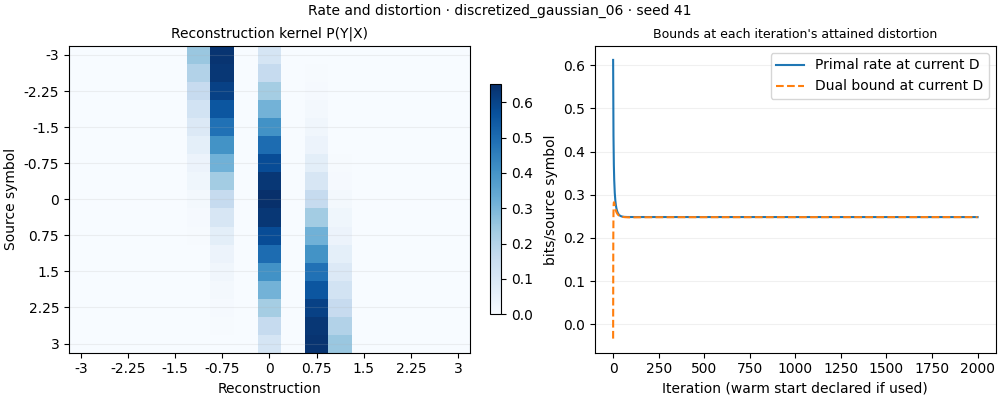

In [5]:
record, path = query("rate_distortion", task="discretized_gaussian", beta=0.7)[0]
measured(record)
preview(record)

The Gaussian case has 17 finite source/reconstruction values and Gaussian CDF bin masses. It is not the continuous Gaussian law. A declared convex marginal warm start addresses slow BA convergence; its certificate remains the same dual gap. Row distortion offsets change the feasible distortion threshold, not mutual information.